# English → ASL Gloss: T5-small fine-tuning

Built for Google Colab (**Runtime → Change runtime type → GPU**).

1. K-fold cross-validation (stratified by `category`) over a small learning-rate grid, scoring every epoch. This runs only when the manual hyperparameters are left blank.
2. The learning rate / epoch count with the best mean validation score is used to train a final model.
3. A stratified hold-out slice (15%) is kept out of training and used to compare the fine-tuned model with an untouched `google-t5/t5-small` baseline, reporting BLEU, chrF, exact match and side-by-side translations.
4. The model is saved with a `gloss_config.json` and zipped for download. Unzip it into `Backend/Models/t5_asl_gloss/` for `SpeechToGloss.py`.

`MANUAL_LEARNING_RATE` and `MANUAL_EPOCHS` are preset to the values stored in `gloss_config.json` (`3e-4`, 29 epochs), so the default run trains once and goes straight to the comparison. Set both to `None` to search the grid again.

To skip training entirely, upload the existing `t5_asl_gloss.zip` when prompted: the notebook loads those weights and runs only the comparison. Note that those weights saw the hold-out during training, so their hold-out scores are optimistic.

In [ ]:
!pip install -q transformers sentencepiece sacrebleu accelerate

In [ ]:
import glob
import json
import os
import random
import shutil
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu
import torch
from sklearn.model_selection import StratifiedKFold, train_test_split
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer, get_linear_schedule_with_warmup

MODEL_NAME = "google-t5/t5-small"
TASK_PREFIX = "translate English to ASL gloss: "
LOWERCASE_TARGETS = True  # T5's vocabulary tokenises lowercase words far better than ALL-CAPS; outputs are upper-cased again

N_FOLDS = 5
LEARNING_RATES = [3e-4, 5e-4, 1e-3]  # grid used only when the manual values below are blank
MAX_EPOCHS = 30                      # schedule horizon for the grid search

# Hyperparameters preset from Backend/Models/t5_asl_gloss/gloss_config.json.
# Set both to None to run the 5-fold search again.
MANUAL_LEARNING_RATE = None
MANUAL_EPOCHS = None

MANUAL_HYPERPARAMETERS = MANUAL_LEARNING_RATE is not None and MANUAL_EPOCHS is not None
if (MANUAL_LEARNING_RATE is None) != (MANUAL_EPOCHS is None):
    print("Set both manual hyperparameters or neither; falling back to the 5-fold search.")

RUN_CV = not MANUAL_HYPERPARAMETERS
if RUN_CV:
    best_lr = best_epoch = None
    SCHEDULE_EPOCHS = MAX_EPOCHS
else:
    best_lr, best_epoch = MANUAL_LEARNING_RATE, int(MANUAL_EPOCHS)
    # Keep the 30-epoch schedule the deployed model was trained with, even when stopping at 29
    SCHEDULE_EPOCHS = max(MAX_EPOCHS, best_epoch)
    print(f"Manual hyperparameters: lr={best_lr:g}, epochs={best_epoch} (cross-validation skipped)")

BATCH_SIZE = 16
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.06
MAX_SOURCE_LEN = 64
MAX_TARGET_LEN = 64
NUM_BEAMS = 4
SELECTION_METRIC = "chrf"  # "chrf", "bleu" or "exact_match"
SEED = 42

DATA_GLOB = "/content/asl_gloss_dataset*.csv"  # picks up part1, part2, ... if you add more
OUTPUT_DIR = "/content/t5_asl_gloss"

# Baseline comparison
COMPARE_FRACTION = 0.15  # stratified slice kept out of training and used for the comparison
USE_UPLOADED_MODEL = True  # set False to always train from google-t5/t5-small
UPLOADED_MODEL_CANDIDATES = [
    "/content/t5_asl_gloss_upload",
    "/content/t5_asl_gloss",
    "/content/drive/MyDrive/t5_asl_gloss",
]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# T5 is unstable in fp16, so only use mixed precision when bf16 is available (A100 / L4, not T4)
USE_BF16 = device.type == "cuda" and torch.cuda.is_bf16_supported()
print(f"Device: {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'} | bf16: {USE_BF16}")

Device: Tesla T4 | bf16: True


## Load the dataset
Upload the CSV(s) when prompted, or copy them into `/content` first (e.g. from Google Drive). A stratified 15% slice is held out here and is never seen by the training code below.

In [ ]:
if not glob.glob(DATA_GLOB):
    from google.colab import files
    os.chdir("/content")
    files.upload()

paths = sorted(glob.glob(DATA_GLOB))
print("Loading:", paths)
df = pd.concat([pd.read_csv(p) for p in paths], ignore_index=True)

df = df.dropna(subset=["english", "gloss"])
df["english"] = df["english"].astype(str).str.strip()
df["gloss"] = df["gloss"].astype(str).str.split().str.join(" ").str.upper()
df["category"] = df["category"].fillna("unknown").astype(str).str.strip()

rows_before = len(df)
df = df.drop_duplicates(subset=["english", "gloss"]).reset_index(drop=True)
print(f"{len(df)} rows ({rows_before - len(df)} duplicates removed)")

conflicts = df.groupby("english")["gloss"].nunique()
if (conflicts > 1).any():
    print("Warning: sentences with more than one gloss:", conflicts[conflicts > 1].index.tolist())

# StratifiedKFold needs at least N_FOLDS rows per class
counts = df["category"].value_counts()
df["strata"] = df["category"].where(df["category"].map(counts) >= N_FOLDS, "other")

# Hold out a slice for the baseline comparison; everything below trains on train_df only
# Stratification needs at least two rows per class, so fall back to a plain split on tiny datasets
stratify_col = df["strata"] if df["strata"].value_counts().min() >= 2 else None
train_df, compare_df = train_test_split(
    df, test_size=COMPARE_FRACTION, random_state=SEED, stratify=stratify_col
)
print(f"Training rows: {len(train_df)} | held-out comparison rows: {len(compare_df)}")

display(counts.to_frame("rows"))
train_df.sample(5, random_state=SEED)

Loading: ['/content/asl_gloss_dataset_part1.csv']
425 rows (0 duplicates removed)
Training rows: 361 | held-out comparison rows: 64


,rows
category,
questions,68
basic_exchange,63
introductions,50
medical,45
daily_life,41
service,36
commands,29
time_tense,29
greetings,27


,english,gloss,category,strata
70,I have one sister.,ME HAVE 1 SISTER,introductions,introductions
73,I have two children.,ME HAVE 2 CHILDREN,introductions,introductions
275,My throat hurts.,MY THROAT HURT,medical,medical
422,I never eat meat.,ME NEVER EAT MEAT,negation,negation
83,"Fine, and you?",FINE YOU,basic_exchange,basic_exchange


## Training / evaluation helpers

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def to_target(gloss):
    return gloss.lower() if LOWERCASE_TARGETS else gloss


def postprocess(text):
    return " ".join(text.upper().split())


def make_loader(tokenizer, sources, targets, shuffle):
    enc = tokenizer([TASK_PREFIX + s for s in sources], max_length=MAX_SOURCE_LEN,
                    truncation=True, padding=True, return_tensors="pt")
    labels = tokenizer(text_target=[to_target(t) for t in targets], max_length=MAX_TARGET_LEN,
                       truncation=True, padding=True, return_tensors="pt").input_ids
    labels[labels == tokenizer.pad_token_id] = -100
    return DataLoader(TensorDataset(enc.input_ids, enc.attention_mask, labels), batch_size=BATCH_SIZE, shuffle=shuffle)


@torch.no_grad()
def translate(model, tokenizer, sentences, batch_size=64):
    model.eval()
    outputs = []
    for i in range(0, len(sentences), batch_size):
        enc = tokenizer([TASK_PREFIX + s for s in sentences[i:i + batch_size]], max_length=MAX_SOURCE_LEN,
                        truncation=True, padding=True, return_tensors="pt").to(device)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=USE_BF16):
            generated = model.generate(**enc, max_new_tokens=MAX_TARGET_LEN, num_beams=NUM_BEAMS)
        outputs += [postprocess(t) for t in tokenizer.batch_decode(generated, skip_special_tokens=True)]
    return outputs


def score(predictions, references):
    return {
        "bleu": sacrebleu.corpus_bleu(predictions, [references]).score,
        "chrf": sacrebleu.corpus_chrf(predictions, [references]).score,
        "exact_match": 100 * float(np.mean([p == r for p, r in zip(predictions, references)])),
    }


def evaluate(frame, model, tokenizer):
    """Predictions and corpus scores for one dataframe of english/gloss pairs."""
    predictions = translate(model, tokenizer, frame["english"].tolist())
    return predictions, score(predictions, frame["gloss"].tolist())


def train_model(train_df, lr, epochs, eval_df=None, stop_after=None):
    """Fine-tunes a fresh T5. The LR schedule always spans `epochs`, so stopping early
    with `stop_after` reproduces exactly what was measured during cross-validation."""
    set_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)

    loader = make_loader(tokenizer, train_df["english"].tolist(), train_df["gloss"].tolist(), shuffle=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    total_steps = len(loader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)

    history = []
    for epoch in range(1, (stop_after or epochs) + 1):
        model.train()
        running_loss = 0.0
        for input_ids, attention_mask, labels in loader:
            input_ids, attention_mask, labels = input_ids.to(device), attention_mask.to(device), labels.to(device)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=USE_BF16):
                loss = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
            running_loss += loss.item()

        record = {"epoch": epoch, "train_loss": running_loss / len(loader)}
        if eval_df is not None:
            predictions = translate(model, tokenizer, eval_df["english"].tolist())
            record.update(score(predictions, eval_df["gloss"].tolist()))
        history.append(record)

    return model, tokenizer, history

## Load the fine-tuned model

`from_pretrained` accepts a local folder, so an uploaded `t5_asl_gloss` directory (or zip) is used directly and training is skipped. If nothing is supplied, the notebook trains from `google-t5/t5-small` as before.

If the folder lives in Drive, mount it first with `from google.colab import drive; drive.mount('/content/drive')`.

In [ ]:
def model_root(base):
    """Returns base, or a single folder inside it, if that folder holds config.json."""
    if os.path.isfile(os.path.join(base, "config.json")):
        return base
    if os.path.isdir(base):
        for name in sorted(os.listdir(base)):
            candidate = os.path.join(base, name)
            if os.path.isfile(os.path.join(candidate, "config.json")):
                return candidate
    return None


def find_uploaded_model():
    for candidate in UPLOADED_MODEL_CANDIDATES:
        root = model_root(candidate)
        if root:
            return root

    # Last resort: any folder copied into /content that holds weights, ignoring the output directory
    for candidate in sorted(glob.glob("/content/*")):
        if os.path.abspath(candidate) == os.path.abspath(OUTPUT_DIR):
            continue
        root = model_root(candidate)
        if root and (os.path.isfile(os.path.join(root, "model.safetensors"))
                     or os.path.isfile(os.path.join(root, "pytorch_model.bin"))):
            return root
    return None


uploaded_dir = find_uploaded_model() if USE_UPLOADED_MODEL else None

# A previously downloaded export can be reused without uploading it again
if USE_UPLOADED_MODEL and uploaded_dir is None:
    for archive in sorted(glob.glob("/content/t5_asl_gloss*.zip")):
        os.makedirs("/content/t5_asl_gloss_upload", exist_ok=True)
        shutil.unpack_archive(archive, "/content/t5_asl_gloss_upload")
        print("Extracted", archive)
    uploaded_dir = find_uploaded_model()

if USE_UPLOADED_MODEL and uploaded_dir is None:
    from google.colab import files
    print("Upload t5_asl_gloss.zip to skip training entirely, or continue without uploading to train from scratch.")
    for name in files.upload():
        if name.lower().endswith(".zip"):
            os.makedirs("/content/t5_asl_gloss_upload", exist_ok=True)
            shutil.unpack_archive(name, "/content/t5_asl_gloss_upload")
    uploaded_dir = find_uploaded_model()

USING_UPLOADED = uploaded_dir is not None
print("Uploaded model:", uploaded_dir if USING_UPLOADED else "not found - a fresh model will be trained")

# The saved model carries its own decoding settings; reuse them so training and the app agree
if USING_UPLOADED:
    config_path = os.path.join(uploaded_dir, "gloss_config.json")
    if os.path.isfile(config_path):
        with open(config_path) as f:
            deployed = json.load(f)
        TASK_PREFIX = deployed.get("task_prefix", TASK_PREFIX)
        MAX_SOURCE_LEN = deployed.get("max_source_len", MAX_SOURCE_LEN)
        MAX_TARGET_LEN = deployed.get("max_target_len", MAX_TARGET_LEN)
        NUM_BEAMS = deployed.get("num_beams", NUM_BEAMS)
        print("Decoding settings from gloss_config.json:",
              f"prefix={TASK_PREFIX!r}, max_source_len={MAX_SOURCE_LEN},",
              f"max_target_len={MAX_TARGET_LEN}, num_beams={NUM_BEAMS}")

Upload t5_asl_gloss.zip to skip training entirely, or continue without uploading to train from scratch.


Uploaded model: not found - a fresh model will be trained


## K-fold cross-validation
Every learning rate is trained on each fold for `MAX_EPOCHS`, with validation scores recorded after every epoch. This section runs only when `MANUAL_LEARNING_RATE` and `MANUAL_EPOCHS` are both `None`; it is also skipped when an uploaded model is used.

In [ ]:
if USING_UPLOADED:
    print("Uploaded model supplied; skipping cross-validation and final training.")
    cv = None
    best_row = best_std = None
elif not RUN_CV:
    print("Hyperparameters were set manually; skipping the 5-fold search.")
    cv = None
    best_row = best_std = None
else:
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    folds = list(skf.split(train_df, train_df["strata"]))

    cv_records = []
    for lr in LEARNING_RATES:
        for fold, (train_idx, val_idx) in enumerate(folds):
            start = time.time()
            model, tokenizer, history = train_model(train_df.iloc[train_idx], lr, MAX_EPOCHS, eval_df=train_df.iloc[val_idx])
            cv_records += [{"lr": lr, "fold": fold, **record} for record in history]

            best = max(history, key=lambda r: r[SELECTION_METRIC])
            print(f"lr={lr:g} fold {fold + 1}/{N_FOLDS}: best {SELECTION_METRIC}={best[SELECTION_METRIC]:.1f} "
                  f"at epoch {best['epoch']} ({time.time() - start:.0f}s)")

            del model
            torch.cuda.empty_cache()

    cv = pd.DataFrame(cv_records)
    cv.to_csv("/content/cv_results.csv", index=False)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

lr=0.0003 fold 1/5: best chrf=92.3 at epoch 18 (111s)


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

lr=0.0003 fold 2/5: best chrf=87.9 at epoch 21 (80s)


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

lr=0.0003 fold 3/5: best chrf=92.6 at epoch 26 (80s)


... (20 outputs left out)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

lr=0.001 fold 4/5: best chrf=90.2 at epoch 9 (84s)


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

lr=0.001 fold 5/5: best chrf=91.9 at epoch 16 (80s)


Best config: lr=0.001, epochs=9
         bleu: 67.67 ± 10.11
         chrf: 90.37 ± 1.25
  exact_match: 77.29 ± 3.67


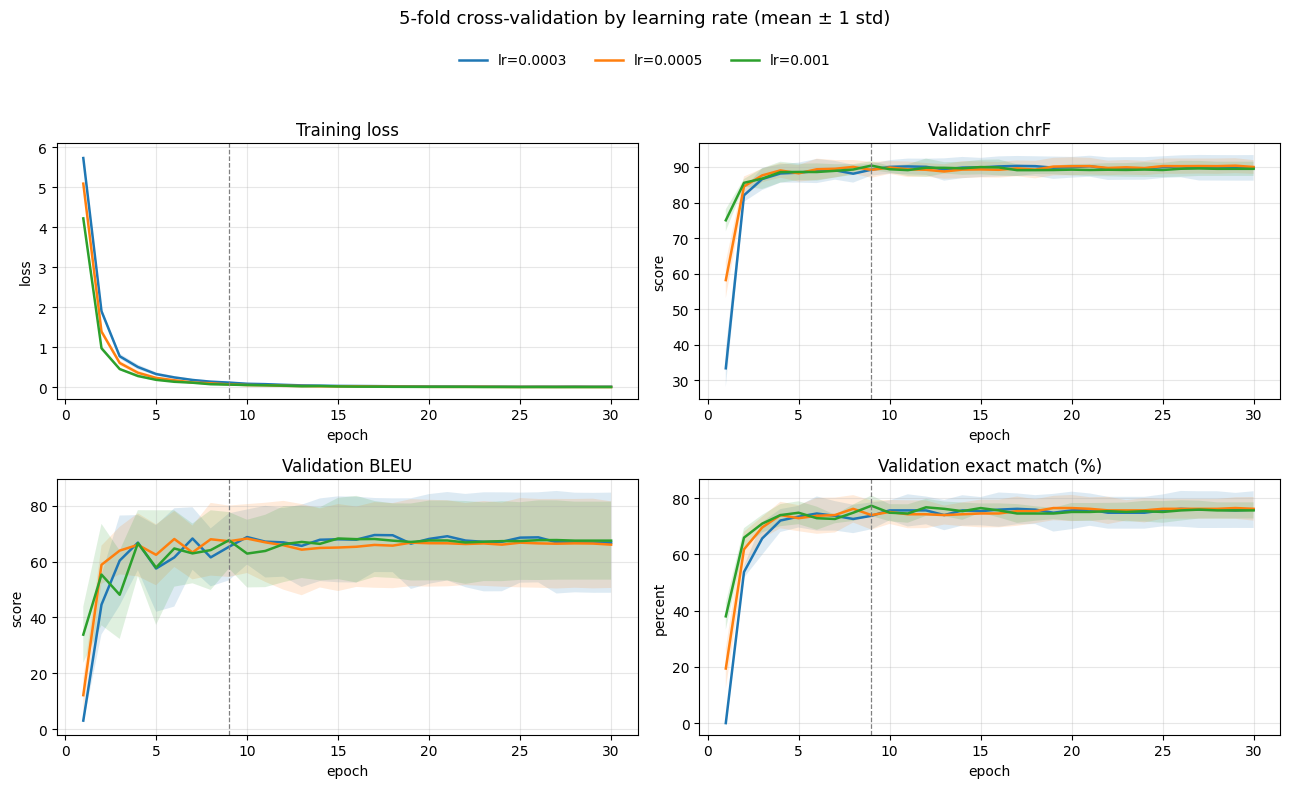

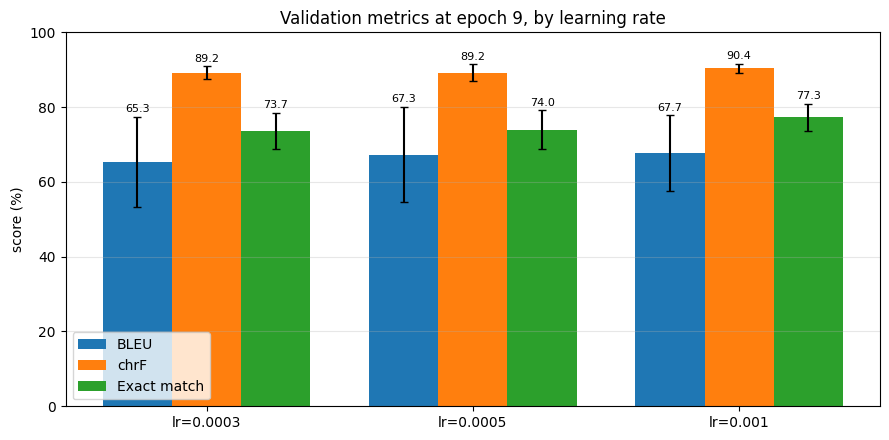

In [ ]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

# The curves come from this run, or from a cv_results.csv kept in /content by an earlier run
if RUN_CV:
    cv_frame = cv
elif os.path.isfile("/content/cv_results.csv"):
    cv_frame = pd.read_csv("/content/cv_results.csv")
    print("Loaded /content/cv_results.csv for the plots.")
else:
    cv_frame = None

if cv_frame is None:
    print("No cross-validation results available; blank the manual hyperparameters to generate the curves.")
else:
    mean_scores = cv_frame.groupby(["lr", "epoch"])[["bleu", "chrf", "exact_match", "train_loss"]].mean()
    std_scores = cv_frame.groupby(["lr", "epoch"])[["bleu", "chrf", "exact_match", "train_loss"]].std()

    chart_lr, chart_epoch = mean_scores[SELECTION_METRIC].idxmax()
    if RUN_CV:
        best_lr, best_epoch = chart_lr, chart_epoch
        best_row = mean_scores.loc[(best_lr, best_epoch)]
        best_std = std_scores.loc[(best_lr, best_epoch)]
        print(f"Best config: lr={best_lr:g}, epochs={best_epoch}")
        for metric in ["bleu", "chrf", "exact_match"]:
            print(f"  {metric:>11}: {best_row[metric]:.2f} ± {best_std[metric]:.2f}")
    else:
        print(f"Best in the loaded history: lr={chart_lr:g}, epoch {chart_epoch} (training still uses the manual values)")

    panels = [
        ("train_loss", "Training loss"),
        ("chrf", "Validation chrF"),
        ("bleu", "Validation BLEU"),
        ("exact_match", "Validation exact match (%)"),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for ax, (metric, title) in zip(axes.ravel(), panels):
        for lr in sorted(cv_frame["lr"].unique()):
            series = mean_scores.loc[lr][metric]
            spread = std_scores.loc[lr][metric]
            ax.plot(series.index, series.values, label=f"lr={lr:g}", linewidth=1.8)
            ax.fill_between(series.index, series.values - spread.values, series.values + spread.values, alpha=0.15)
        ax.axvline(chart_epoch, color="grey", linestyle="--", linewidth=0.9)
        ax.set_title(title)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
    axes[0, 0].set_ylabel("loss")
    axes[0, 1].set_ylabel("score")
    axes[1, 0].set_ylabel("score")
    axes[1, 1].set_ylabel("percent")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.suptitle("5-fold cross-validation by learning rate (mean ± 1 std)", fontsize=13, y=0.98)
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 0.94), frameon=False)
    fig.tight_layout(rect=[0, 0, 1, 0.9])
    fig.savefig(os.path.join(OUTPUT_DIR, "cv_curves.png"), dpi=150, bbox_inches="tight")
    plt.show()

    at_best = mean_scores.xs(chart_epoch, level="epoch")
    at_best_std = std_scores.xs(chart_epoch, level="epoch")
    shown = ["bleu", "chrf", "exact_match"]
    x = np.arange(len(at_best.index))
    width = 0.26
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for offset, metric, label in zip([-width, 0, width], shown, ["BLEU", "chrF", "Exact match"]):
        bars = ax.bar(x + offset, at_best[metric].values, width,
                      yerr=at_best_std[metric].values, capsize=3, label=label)
        ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
    ax.set_xticks(x, [f"lr={lr:g}" for lr in at_best.index])
    ax.set_ylabel("score (%)")
    ax.set_ylim(0, 100)
    ax.set_title(f"Validation metrics at epoch {chart_epoch}, by learning rate")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, "cv_best_by_lr.png"), dpi=150, bbox_inches="tight")
    plt.show()

## Obtain the fine-tuned model

If a model folder or zip was supplied, it is copied into `OUTPUT_DIR` and loaded. Otherwise a fresh model is trained on the best configuration and saved, with `gloss_config.json` describing the decoding settings.

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Final train loss: 0.0638


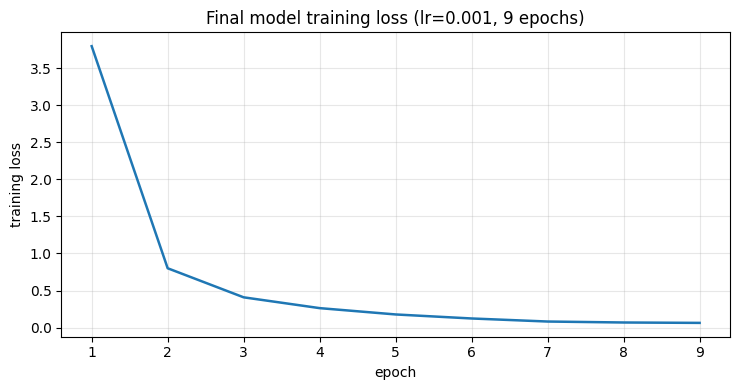

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model directory: /content/t5_asl_gloss


In [ ]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

if USING_UPLOADED:
    if os.path.abspath(uploaded_dir) != os.path.abspath(OUTPUT_DIR):
        shutil.copytree(uploaded_dir, OUTPUT_DIR, dirs_exist_ok=True)
    model = AutoModelForSeq2SeqLM.from_pretrained(OUTPUT_DIR).to(device)
    tokenizer = AutoTokenizer.from_pretrained(OUTPUT_DIR)
    print(f"Loaded the uploaded model from {uploaded_dir}; final training skipped.")
else:
    model, tokenizer, history = train_model(train_df, best_lr, SCHEDULE_EPOCHS, stop_after=best_epoch)
    print(f"Final train loss: {history[-1]['train_loss']:.4f}")

    fig, ax = plt.subplots(figsize=(7.5, 4))
    ax.plot([record["epoch"] for record in history], [record["train_loss"] for record in history], linewidth=1.8)
    ax.set_xlabel("epoch")
    ax.set_ylabel("training loss")
    ax.set_title(f"Final model training loss (lr={best_lr:g}, {len(history)} epochs)")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, "final_training_loss.png"), dpi=150, bbox_inches="tight")
    plt.show()

    model.save_pretrained(OUTPUT_DIR)
    tokenizer.save_pretrained(OUTPUT_DIR)

    # Read by SpeechToGloss.py so inference matches training exactly
    with open(os.path.join(OUTPUT_DIR, "gloss_config.json"), "w") as f:
        json.dump({
            "base_model": MODEL_NAME,
            "task_prefix": TASK_PREFIX,
            "lowercase_targets": LOWERCASE_TARGETS,
            "max_source_len": MAX_SOURCE_LEN,
            "max_target_len": MAX_TARGET_LEN,
            "num_beams": NUM_BEAMS,
            "learning_rate": best_lr,
            "epochs": int(best_epoch),
            "cv_scores": None if best_row is None else
                         {m: round(float(best_row[m]), 2) for m in ["bleu", "chrf", "exact_match"]},
        }, f, indent=2)

print("Model directory:", OUTPUT_DIR)

## Baseline comparison

The fine-tuned model and an untouched `google-t5/t5-small` are scored on the held-out slice with identical prompts and decoding settings.

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

,model,bleu,chrf,exact_match
0,t5-small (zero-shot),0.69,17.40,0.00
1,fine-tuned,68.43,93.95,81.25


Fine-tuned minus zero-shot: bleu +67.74 | chrf +76.55 | exact_match +81.25


,english,reference,t5-small,fine-tuned
0,Good night.,GOOD NIGHT,ASL GLOSS: GOOD NIGHT.,GOOD NIGHT
1,Maybe.,MAYBE,ASL GLOSS: MAYBE.,MAYBE
2,The meeting is at three o'clock.,MEETING 3 O'CLOCK,ASL GLOSS: DIE SITZUNG IST UM DREI UHR.,MEETING 3 O CLOCK
3,What's your name?,YOUR NAME WHAT,ASL GLOSS: WAS IST DEIN NAME?,YOUR NAME WHAT
4,This is my sister.,THIS MY SISTER,ASL GLOSS: DIES IST MEINE SCHWESTER.,THIS MY SISTER
5,I can swim.,ME CAN SWIM,ASL GLOSS: ICH KANN SCHWIMMEN.,ME CAN SWIM
6,Where is my phone?,MY PHONE WHERE,ASL GLOSS: WO IST MEIN TELEFON?,MY PHONE WHERE
7,Don't be late.,LATE NOT,ASL GLOSS: SEIEN SIE NICHT VERSPÄTET.,LATE NOT
8,I need a receipt.,ME NEED RECEIPT,ASL GLOSS: ICH BENÖTIGE EINEN EMPFANG.,ME NEED RECEIPT
9,You're welcome.,WELCOME,ASL GLOSS: SIE SIND WILLKOMMEN.,YOU WELCOME


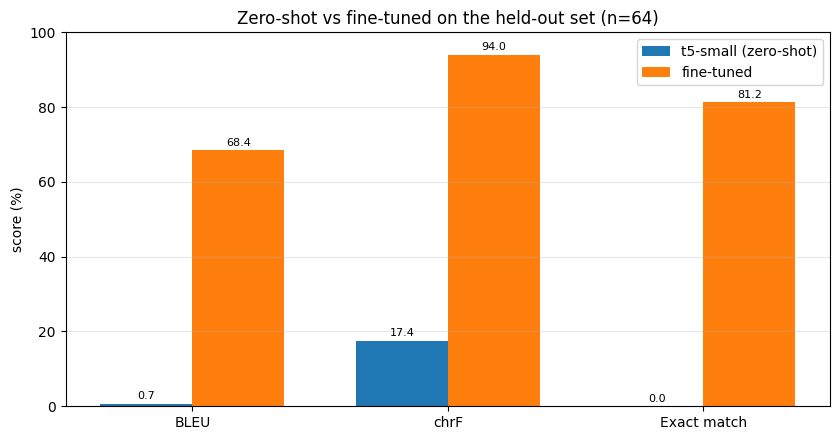

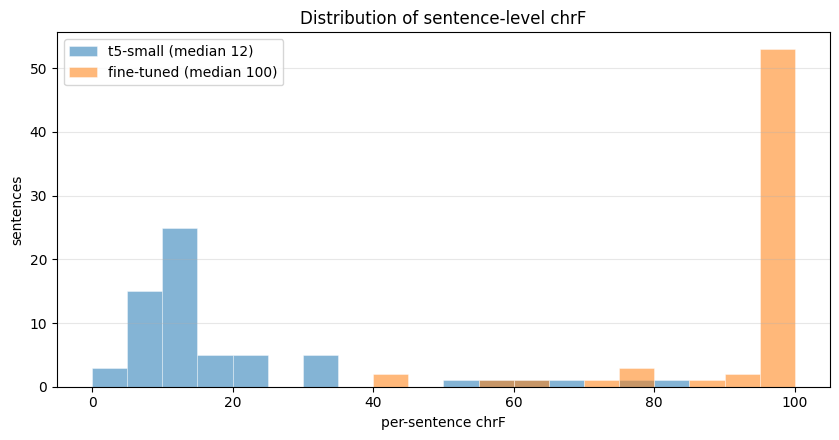

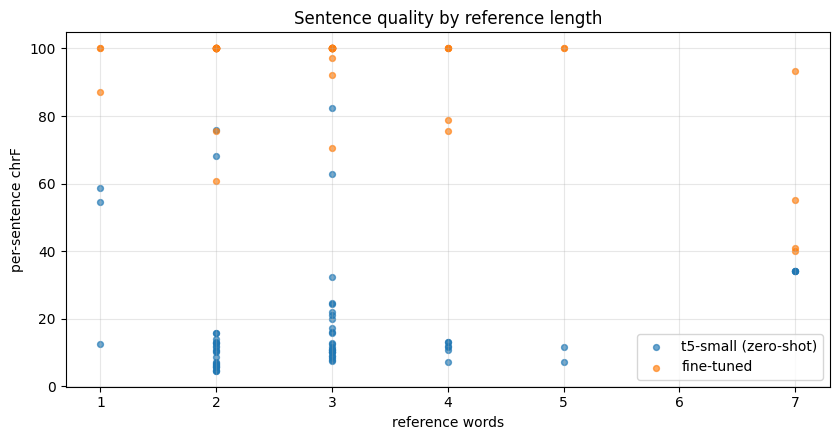

Median sentence chrF: t5-small 11.8, fine-tuned 100.0


In [ ]:
# Untouched t5-small, same prompt format and decoding settings
baseline_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
baseline_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)

baseline_predictions, baseline_scores = evaluate(compare_df, baseline_model, baseline_tokenizer)
tuned_predictions, tuned_scores = evaluate(compare_df, model, tokenizer)

comparison = pd.DataFrame([
    {"model": "t5-small (zero-shot)", **baseline_scores},
    {"model": "fine-tuned", **tuned_scores},
])
delta = {metric: tuned_scores[metric] - baseline_scores[metric] for metric in ["bleu", "chrf", "exact_match"]}

display(comparison.round(2))
print("Fine-tuned minus zero-shot:", " | ".join(f"{metric} {value:+.2f}" for metric, value in delta.items()))

comparison.to_csv(os.path.join(OUTPUT_DIR, "comparison_scores.csv"), index=False)

examples = pd.DataFrame({
    "english": compare_df["english"].values,
    "reference": compare_df["gloss"].values,
    "t5-small": baseline_predictions,
    "fine-tuned": tuned_predictions,
})
examples.to_csv(os.path.join(OUTPUT_DIR, "comparison_examples.csv"), index=False)
display(examples.head(10))

if USING_UPLOADED:
    print("NOTE: the uploaded weights were trained on the full dataset before this hold-out was created,")
    print("      so their scores here are optimistic. The novel-sentence table below is the clean comparison.")


def per_sentence_chrf(predictions, references):
    """chrF for each pair, via the corpus function so it works on every sacrebleu version."""
    return [sacrebleu.corpus_chrf([p], [[r]]).score for p, r in zip(predictions, references)]


references = compare_df["gloss"].tolist()
baseline_sentence = per_sentence_chrf(baseline_predictions, references)
tuned_sentence = per_sentence_chrf(tuned_predictions, references)

# 1. Headline metrics on the held-out slice
metric_keys = ["bleu", "chrf", "exact_match"]
metric_labels = ["BLEU", "chrF", "Exact match"]
x = np.arange(len(metric_keys))
width = 0.36
fig, ax = plt.subplots(figsize=(8.5, 4.5))
zero = ax.bar(x - width / 2, [baseline_scores[m] for m in metric_keys], width, label="t5-small (zero-shot)")
tuned = ax.bar(x + width / 2, [tuned_scores[m] for m in metric_keys], width, label="fine-tuned")
ax.bar_label(zero, fmt="%.1f", padding=2, fontsize=8)
ax.bar_label(tuned, fmt="%.1f", padding=2, fontsize=8)
ax.set_xticks(x, metric_labels)
ax.set_ylim(0, 100)
ax.set_ylabel("score (%)")
ax.set_title(f"Zero-shot vs fine-tuned on the held-out set (n={len(compare_df)})")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "comparison_scores.png"), dpi=150, bbox_inches="tight")
plt.show()

# 2. How the improvement is distributed across sentences
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bins = np.linspace(0, 100, 21)
ax.hist(baseline_sentence, bins=bins, alpha=0.55, edgecolor="white", linewidth=0.5,
        label=f"t5-small (median {np.median(baseline_sentence):.0f})")
ax.hist(tuned_sentence, bins=bins, alpha=0.55, edgecolor="white", linewidth=0.5,
        label=f"fine-tuned (median {np.median(tuned_sentence):.0f})")
ax.set_xlabel("per-sentence chrF")
ax.set_ylabel("sentences")
ax.set_title("Distribution of sentence-level chrF")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "comparison_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

# 3. Quality against reference length, which shows where each model starts to struggle
lengths = compare_df["gloss"].str.split().str.len().values
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.scatter(lengths, baseline_sentence, s=18, alpha=0.65, label="t5-small (zero-shot)")
ax.scatter(lengths, tuned_sentence, s=18, alpha=0.65, label="fine-tuned")
ax.set_xlabel("reference words")
ax.set_ylabel("per-sentence chrF")
ax.set_title("Sentence quality by reference length")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "comparison_by_length.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"Median sentence chrF: t5-small {np.median(baseline_sentence):.1f}, fine-tuned {np.median(tuned_sentence):.1f}")

## Novel sentences

Neither model has been trained on these sentences, so this is the clean qualitative comparison.

In [ ]:
# Sentences not in the dataset, run through both models
novel_sentences = [
    "Hello, my name is Sarah.",
    "Where is the library?",
    "I am going to the hospital tomorrow.",
    "Do you want some coffee?",
    "I don't understand the question.",
    "My sister is a doctor.",
]

novel = pd.DataFrame({
    "english": novel_sentences,
    "t5-small": translate(baseline_model, baseline_tokenizer, novel_sentences),
    "fine-tuned": translate(model, tokenizer, novel_sentences),
})
display(novel)
novel.to_csv(os.path.join(OUTPUT_DIR, "comparison_novel.csv"), index=False)

,english,t5-small,fine-tuned
0,"Hello, my name is Sarah.","ASL GLOSS: HALLO, MEIN NAME IST SARAH.",HELLO MY NAME J O H N
1,Where is the library?,ASL GLOSS: WO IST DIE BIBLIOTHEK?,LIBRARY WHERE
2,I am going to the hospital tomorrow.,ASL GLOSS: ICH WERDE MORGEN INS KRANKENHAUS GE...,TOMORROW ME GO HOSPITAL
3,Do you want some coffee?,ASL GLOSS: WOLLEN SIE KAFFEE?,YOU WANT COFFEE
4,I don't understand the question.,ASL GLOSS: ICH VERSTEHE DIE FRAGE NICHT.,ME UNDERSTAND NOT
5,My sister is a doctor.,ASL GLOSS: MEINE SCHWESTER IST ARZT.,MY SISTER DOCTOR


## Export

Downloads `t5_asl_gloss.zip`, which now also contains the comparison CSVs and the figures:

- `cv_curves.png` — training loss, chrF, BLEU and exact match by epoch for each learning rate (mean ± 1 std)
- `cv_best_by_lr.png` — validation metrics at the best epoch, grouped by learning rate
- `final_training_loss.png` — loss curve of the final run
- `comparison_scores.png` — zero-shot vs fine-tuned headline metrics
- `comparison_distribution.png` — per-sentence chrF distribution
- `comparison_by_length.png` — per-sentence chrF against reference length

Optionally also copies the archive to Google Drive.

In [ ]:
COPY_TO_DRIVE = False

# comparison_scores.csv, comparison_examples.csv and comparison_novel.csv are written into OUTPUT_DIR before this cell
archive = shutil.make_archive(OUTPUT_DIR, "zip", OUTPUT_DIR)

if COPY_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copy(archive, "/content/drive/MyDrive/")
    if os.path.isfile("/content/cv_results.csv"):
        shutil.copy("/content/cv_results.csv", "/content/drive/MyDrive/")

from google.colab import files
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>